# 通用设置

In [1]:
import sys
sys.path.append(r'./ETGEM/etgems_web/')
import ETGEM.etgems_web.script
from ETGEM.etgems_web.script.io.json import *
from ETGEM.etgems_web.script.tcmodel.construct import get_K_value
from ETGEM.etgems_web.script.plotting.plotting import *
import numpy as np
from ETGEM.etgems_web.script.analysis.flux_balance_analysis import *
from ETGEM.etgems_web.script.analysis.max_driving_force import *
import copy

cobra.Configuration.solver="gurobi"
metabolites_list = ["cpd00393", 'cpd00121', 'cpd00218','cpd00220',  \
    'cpd00128','cpd00122','cpd00054','cpd00084','cpd00041','cpd00161'\
            ,'cpd00051','cpd00039','cpd00322','cpd00066','cpd00129','cpd00069' \
            ,'cpd00156','cpd00060','cpd00065','cpd00119','cpd00107' \
            ]
aa_rxn = ['EX_fol_e', 'EX_inost_e', 'EX_nac_e','EX_ribflv_e'
    ,'EX_ade_e', 'EX_ser_L_e', 'EX_cys__L_e','EX_asp_L_e', 'EX_thr_L_e'
        , 'EX_arg__L_e', 'EX_lys_L_e'
    , 'EX_ile_L_e', 'EX_phe_L_e', 'EX_pro_L_e', 'EX_tyr_L_e'
    , 'EX_val_L_e', 'EX_met__L_e', 'EX_trp_L_e', 'EX_his_L_e', 'EX_leu_L_e','EX_h_e_reverse'
]

def add_exchange_rxn(model, met_id: str, unlimited=True):
    """
    给代谢物添加交换反应，并设置无限供应
    """
    met = model.get_metabolite_by_id(met_id)
    rxn = Reaction(f"EX_{met_id}")
    rxn.add_metabolites({met: -1})
    
    if unlimited:
        rxn.bounds = (-1000, 1000)  # 无限进出
    else:
        rxn.bounds = (0, 1000)       # 只出不进
        
    model.add_reaction(rxn)
    # print(f"✅ 添加成功：EX_{met_id}，无限供应={unlimited}")
    return model

In [2]:
model_path = "./model/ETiZM564_MM_optimized.json"
sub = []
biomass = {}
etoh= {}
# 定义要模拟的 SYN_num 列表
SYN_list = [0, 8]  # 根据需要修改

# 颜色列表，方便区分不同曲线
colors = ['red', 'blue', 'green', 'purple', 'orange', 'brown']

# 对每个 SYN_num 进行模拟
for idx, SYN_num in enumerate(SYN_list):
    model = read_json_model(model_path)
    sub = []
    biomass[SYN_num], etoh[SYN_num] = [], []
    
    # 添加 sink reactions 和 medium
    for met in metabolites_list:
        cpd_name = met+"_c0"
        try:
            model.add_sink_reaction(cpd_name)
        except:
            pass
        SK_rxn = "SK_"+cpd_name
        model.add_medium(SK_rxn,SYN_num)
    print(model.medium)
    # for sk in model.reactions:
    #     if 'SK_' in sk:
    #         print(model.reactions[sk].bounds)

    model.add_medium("EX_o2_e_reverse", 1000)
    model.get_reaction_by_id("EX_o2_e_reverse").bounds = (0, 1000)
    # 模拟不同葡萄糖摄取速率
    for g in np.arange(0, 86, 1):
        print(SYN_num,g)
        sub.append(g)
        model.obj_name = "ZM_BIOMASS"
        try:
            model.add_medium("EX_glc_D_e_reverse", g)
            opt_etm = calculate_ETM(model, "maximize", 0.0)
            if opt_etm.obj() == None:
                biomass[SYN_num].append(0)
            else:
                biomass[SYN_num].append(opt_etm.obj())
        except:
            biomass[SYN_num].append(0)
        etoh[SYN_num].append(opt_etm.reaction["EX_etoh_e"].value)

{'EX_ca2_e': 1000.0, 'EX_cd2_e': 1000.0, 'EX_cl_e': 1000.0, 'EX_cobalt2_e': 1000.0, 'EX_cu2_e': 1000.0, 'EX_fe2_e': 1000.0, 'EX_fe3_e': 1000.0, 'EX_glc_D_e': 10.0, 'EX_h_e': 1000.0, 'EX_h2o_e': 1000.0, 'EX_hg2_e': 1000.0, 'EX_k_e': 1000.0, 'EX_mg2_e': 1000.0, 'EX_mn2_e': 1000.0, 'EX_mobd_e': 1000.0, 'EX_na1_e': 1000.0, 'EX_nh4_e': 1000.0, 'EX_Pb_e': 1000.0, 'EX_pi_e': 1000.0, 'EX_so4_e': 1000.0, 'EX_thm_e': 1000.0, 'EX_zn2_e': 1000.0, 'EX_pnto_R_e': 1000.0, 'EX_btn_e': 1000.0, 'EX_glc_D_e_reverse': 65, 'EX_o2_e_reverse': 0, 'SK_cpd00393_c0': 0, 'SK_cpd00121_c0': 0, 'SK_cpd00218_c0': 0, 'SK_cpd00220_c0': 0, 'SK_cpd00128_c0': 0, 'SK_cpd00122_c0': 0, 'SK_cpd00054_c0': 0, 'SK_cpd00084_c0': 0, 'SK_cpd00041_c0': 0, 'SK_cpd00161_c0': 0, 'SK_cpd00051_c0': 0, 'SK_cpd00039_c0': 0, 'SK_cpd00322_c0': 0, 'SK_cpd00066_c0': 0, 'SK_cpd00129_c0': 0, 'SK_cpd00069_c0': 0, 'SK_cpd00156_c0': 0, 'SK_cpd00060_c0': 0, 'SK_cpd00065_c0': 0, 'SK_cpd00119_c0': 0, 'SK_cpd00107_c0': 0}
0 0
0 1
0 2
0 3
0 4
0 5
0 6
0

[0, 0, 0.0025266673437326437, 0.01066956913675619, 0.017780299857401753, 0.024890995388689025, 0.032001926010255304, 0.039112793034971866, 0.046221511454541495, 0.053331936394685434, 0.060439859450127704, 0.06755646927222027, 0.07466738833153276, 0.0817784356083415, 0.08888922645015705, 0.0960001455094693, 0.10311106456878152, 0.11022198362809382, 0.11733290268740586, 0.12444290033014875, 0.1315423553315, 0.1386526049196375, 0.14576963872624585, 0.15287310409591184, 0.15998335368404915, 0.16710933610259118, 0.17421133311075182, 0.18133104984612491, 0.18842434941180172, 0.19555301233983985, 0.20266393139915206, 0.20975493784896115, 0.21688576951777652, 0.22397559997728456, 0.23110760763639987, 0.23819609915355894, 0.24532762926776985, 0.2524403648143383, 0.2595512838736483, 0.2666622029329601, 0.2737731219922736, 0.28088404105158543, 0.28796784627051986, 0.2949126164681152, 0.30180211995680667, 0.3087103743076868, 0.3156252902353818, 0.3224150965015292, 0.3291806631106364, 0.33584450674

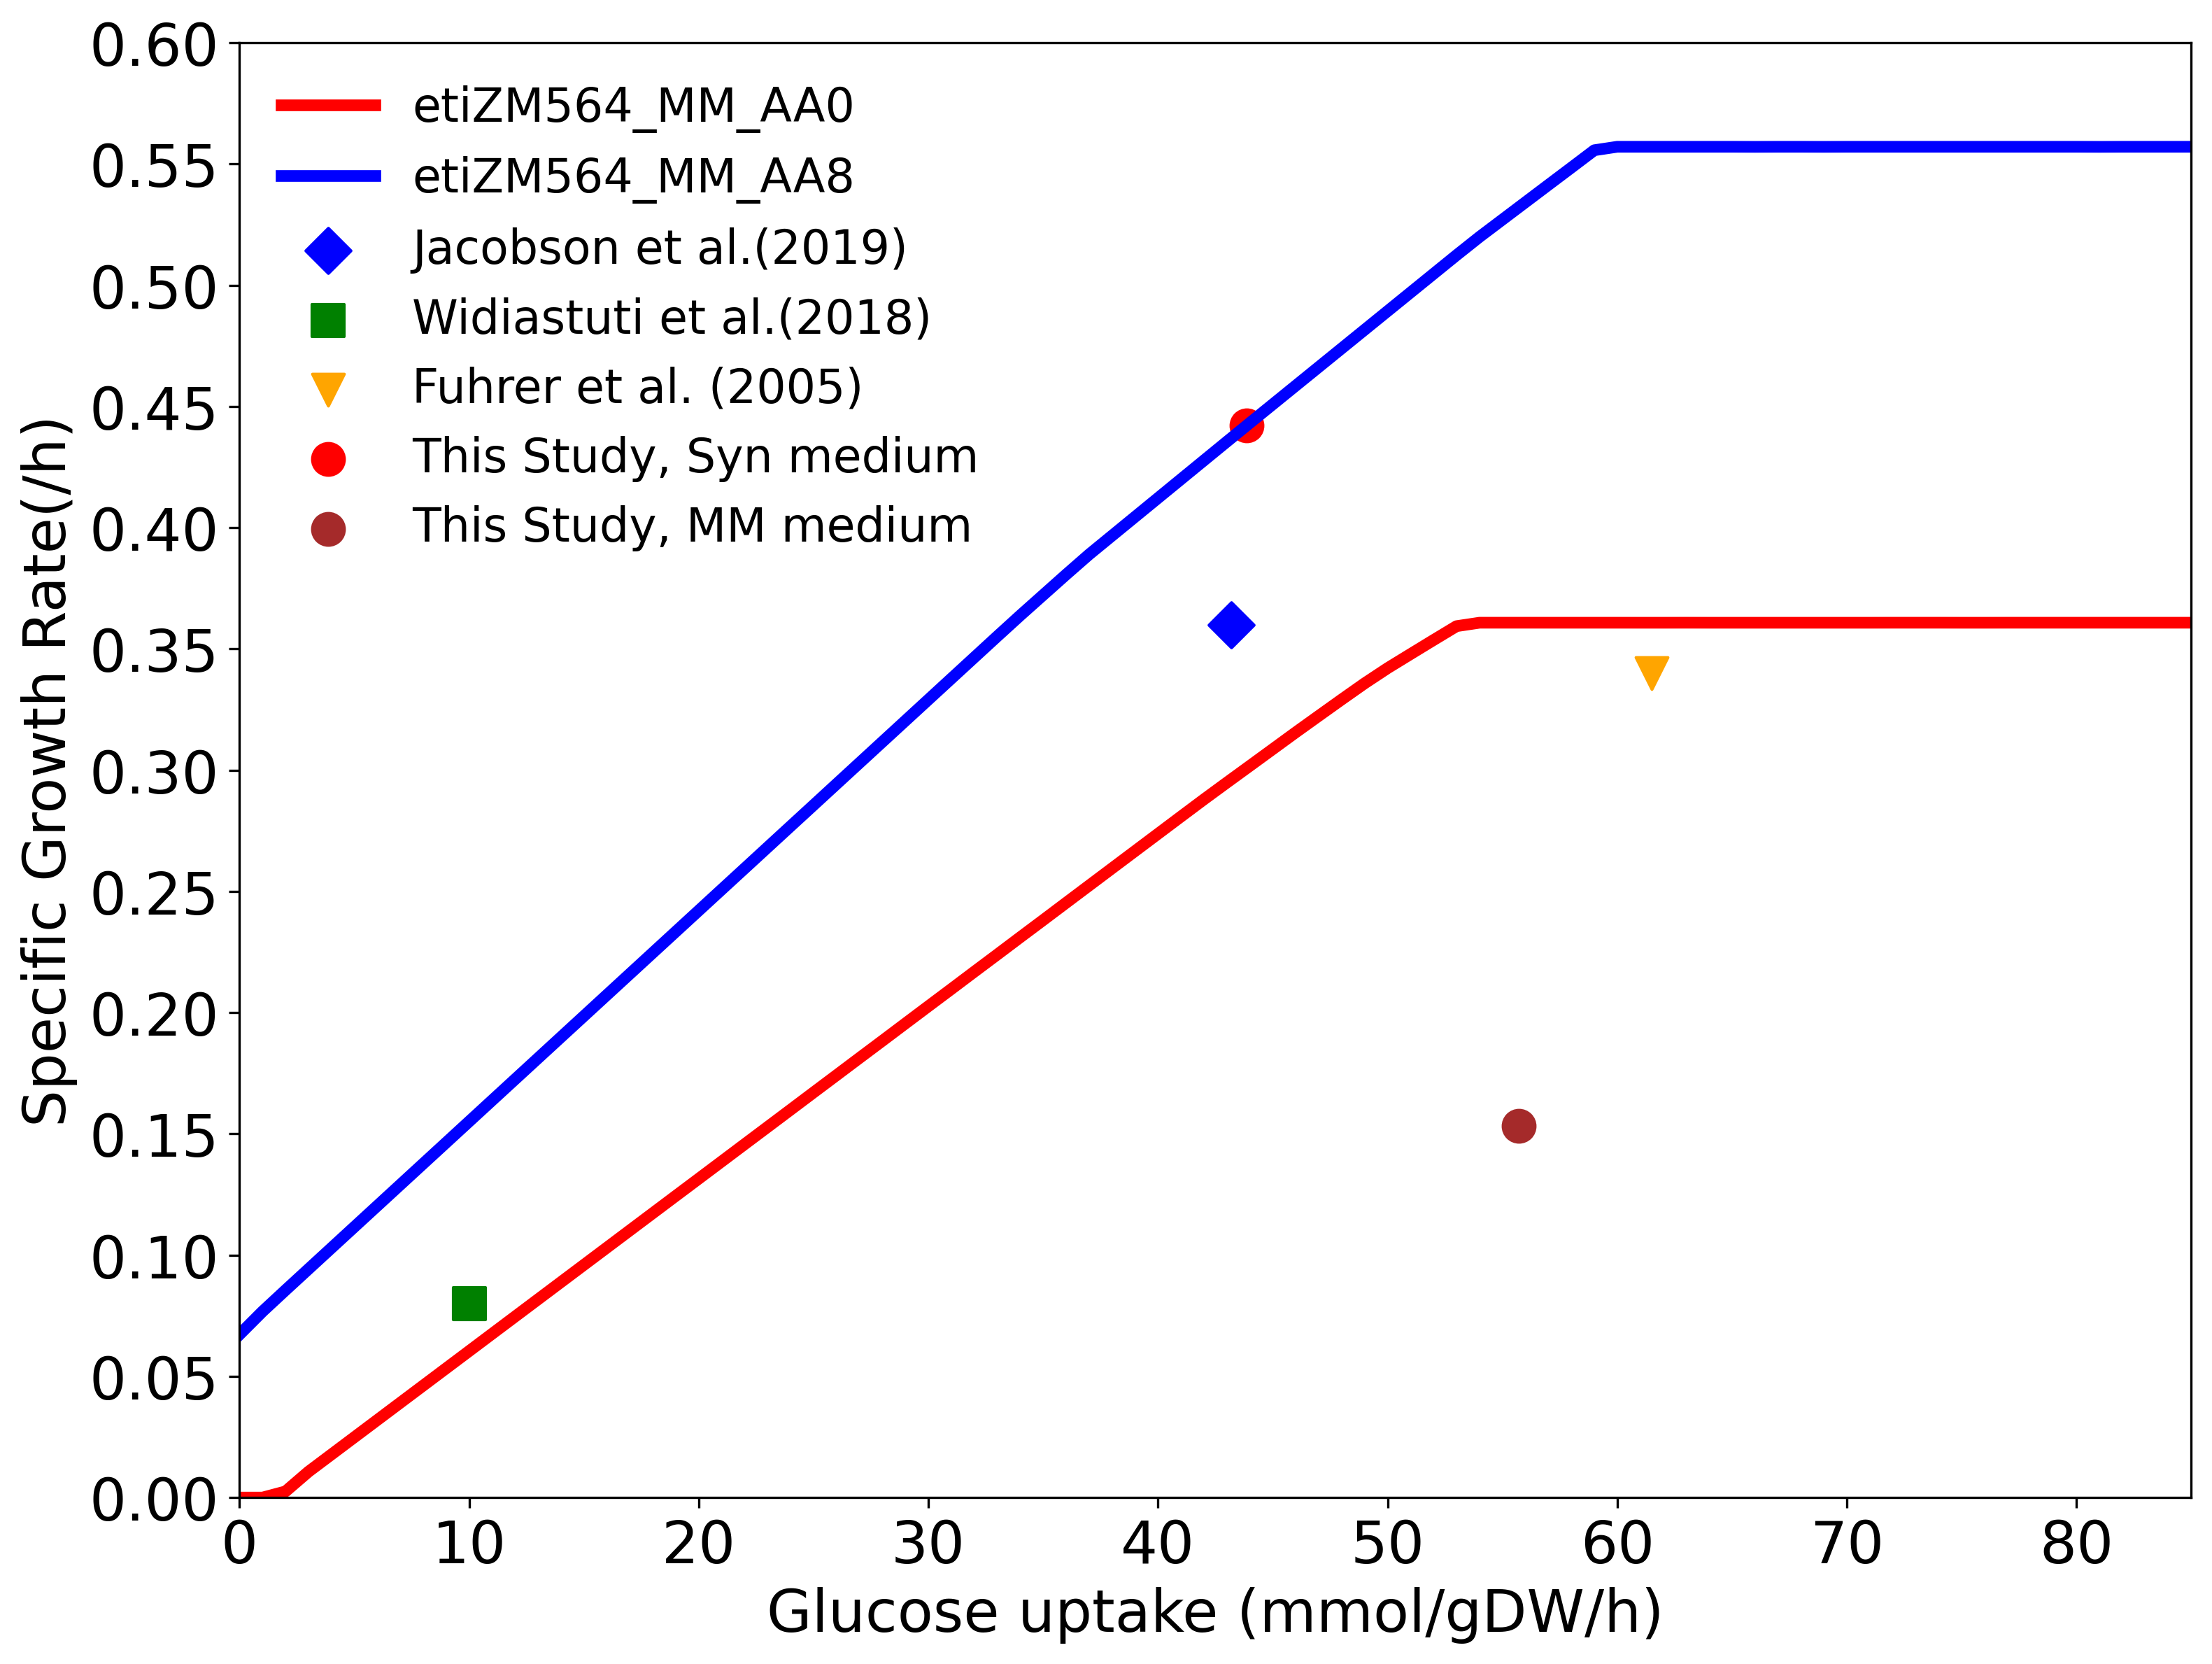

In [3]:
# 创建图形
plt.figure(figsize=(12, 9), dpi=300)
ax = plt.gca()   
# 绘制当前 SYN_num 的曲线
for idx, SYN_num in enumerate(SYN_list):
    plt.plot(sub, biomass[SYN_num], label=f"etiZM564_MM_AA{SYN_num}", 
            linewidth=4, color=colors[idx % len(colors)], markersize=12)
    print(biomass[SYN_num]) 

marker_size = 120
# 添加实验数据点（只添加一次）
plt.scatter(43.2, 0.36, marker='D', color='blue', label="Jacobson et al.(2019)", s=marker_size)
plt.scatter(10, 0.08, marker='s', color='green', label="Widiastuti et al.(2018)", s=marker_size)
plt.scatter(61.5, 0.34, marker='v', color='orange', label="Fuhrer et al. (2005)", s=marker_size)
plt.scatter(43.87, 0.4422, color='red', label="This Study, Syn medium", s=marker_size)
plt.scatter(55.71, 0.1533, color='brown', label="This Study, MM medium", s=marker_size)

# 图形美化
fs = 20
x_min_tick = 0
x_max_tick = np.ceil(max(sub)) if sub else 10
x_tick_step = 10
plt.xticks(np.arange(x_min_tick, x_max_tick + 1, x_tick_step))
plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)
ax.set_yticks(np.arange(0, 0.61, 0.05))
plt.xlabel("Glucose uptake (mmol/gDW/h)", fontsize=fs)
plt.ylabel("Specific Growth Rate(/h)", fontsize=fs)
plt.legend(loc=0, fontsize=fs-4, frameon=False)
ax.set_ylim(0, 0.6)
ax.set_xlim(0, 85)

plt.savefig(f'iZM564_multiple_MM_OD_comparison.png')
plt.savefig(f'iZM564_multiple_MM_OD_comparison.svg')
plt.show()

{0: [None, None, 0.0, 1.5776055269391813, 3.576530197509049, 5.575457162186147, 7.574379367680159, 9.573302762136418, 11.572844463915683, 13.571905935216991, 15.570094414208908, 17.568992448751743, 19.567914870405595, 21.566836883985133, 23.565759713713245, 25.564682135367068, 27.56360455702091, 29.56252697867475, 31.56144940032858, 33.56063111702168, 35.559347320166296, 37.55827261076203, 39.55909212217173, 41.556123191953525, 43.55504848254926, 45.55390635190539, 47.555339520252154, 49.55178619549967, 51.55075038364234, 53.54959603852073, 55.54851846017454, 57.54757137716633, 59.54636330348223, 61.54537609791093, 63.54420814679009, 65.54322667910239, 67.54256416620399, 69.54097541175136, 71.53989783340504, 73.53882025505912, 75.53774267671277, 77.53666509836674, 79.53570371327255, 81.4378199467601, 83.33124208729365, 85.2243741594995, 87.1174031797803, 88.94602483803057, 90.74837055855086, 92.65021796018374, 94.49588927402448, 96.07428603595648, 97.65413802984108, 99.26779069156049, 

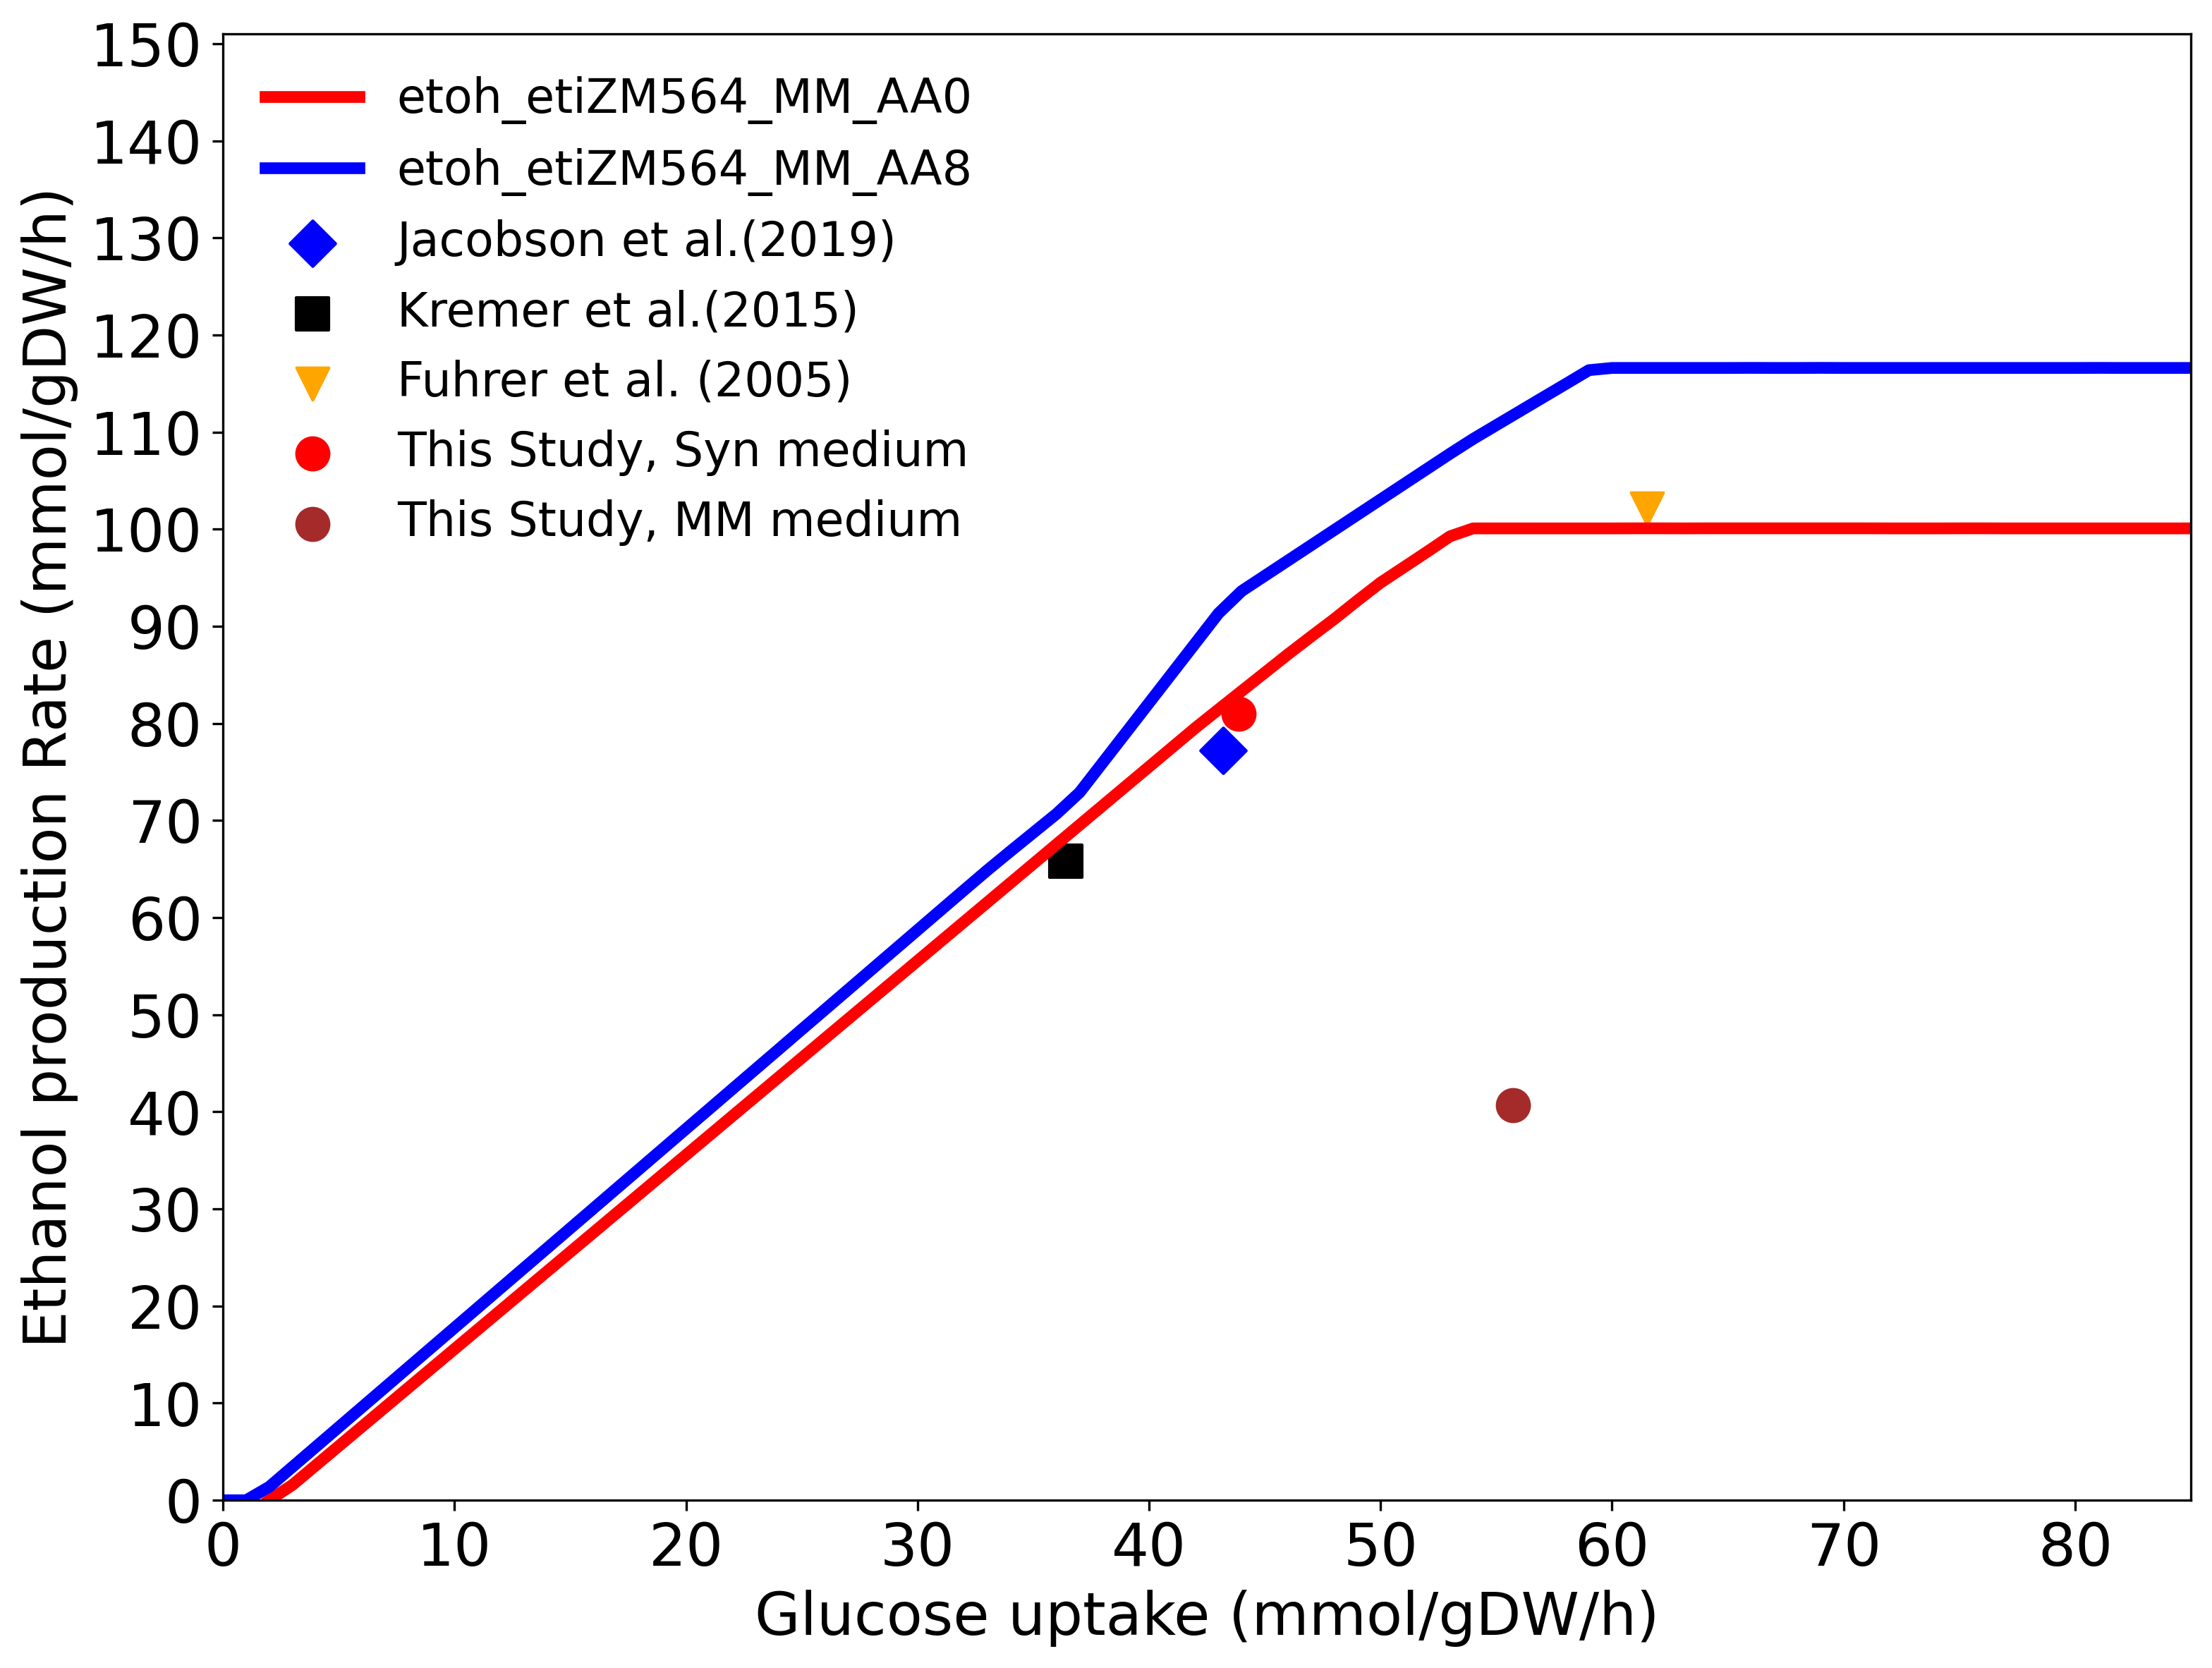

In [4]:
print(etoh)
print(sub)
# 创建图形
plt.figure(figsize=(12, 9), dpi=300)
ax = plt.gca()

# 绘制当前 SYN_num 的曲线
for idx, SYN_num in enumerate(SYN_list):
    plt.plot(sub, etoh[SYN_num], label=f"etoh_etiZM564_MM_AA{SYN_num}", 
            linewidth=4, color=colors[idx % len(colors)], markersize=12)

# 添加实验数据点（只添加一次）
plt.scatter(43.2,77.2,marker = 'D',label="Jacobson et al.(2019)", color = 'blue', s=marker_size)
plt.scatter(36.4,65.8,marker = 's',label="Kremer et al.(2015)", color = 'k', s=marker_size)
plt.scatter(61.5,102.1,marker = 'v',label="Fuhrer et al. (2005)", color = 'orange', s=marker_size)
plt.scatter(43.87,81.01,color = 'red',label="This Study, Syn medium", s=marker_size)
plt.scatter(55.71,40.66,color = 'brown',label="This Study, MM medium", s=marker_size)

# 图形美化
fs = 20
x_min_tick = 0
x_max_tick = np.ceil(max(sub)) if sub else 10
x_tick_step = 10
plt.xticks(np.arange(x_min_tick, x_max_tick + 1, x_tick_step))
plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)
ax.set_yticks(np.arange(0, 151, 10))
plt.xlabel("Glucose uptake (mmol/gDW/h)", fontsize=fs)
plt.ylabel("Ethanol production Rate (mmol/gDW/h)", fontsize=fs)
plt.legend(loc=0, fontsize=fs-4, frameon=False)
ax.set_ylim(0, 151)
ax.set_xlim(0, 85)

plt.savefig(f'iZM564_Ethanol_multiple_MM_comparison.png')
plt.savefig('iZM564_Ethanol_multiple_MM_comparison.svg')
plt.show()

In [5]:
for i in metabolites_list:
    print(f"{model.metabolites[i+'_c0'].name}\t{opt_etm.reaction['SK_'+i+'_c0'].value}")

for j in model.reactions:
    if "EX_" in j and opt_etm.reaction[j].value > 1e-4:
        print(f"{model.reactions[j].name}\t{j}\t{opt_etm.reaction[j].value}")

# for j in model.reactions:
#     if opt_etm.reaction[j].value > 1e-4:
#         print(f"{j}\t{model.reactions[j].build_reaction_string(model,use_metabolite_names=True)}\t{model.reactions[j].bounds}\t{opt_etm.reaction[j].value:.3f}")


Folate	2.8084652391228565e-05
L-Inositol	0.01665346577579474
Niacin	3.559680178822698e-05
Riboflavin	4.32430575103932e-05
Adenine	0.14282194036655968
N-Acetyl-D-glucosamine	0.0
L-Serine	8.0
L-Cysteine	0.012472082203203855
L-Aspartate	8.0
L-Threonine	8.0
L-Arginine	0.10643629666084743
L-Lysine	0.14933061863022432
L-Isoleucine	0.22667115037843502
L-Phenylalanine	0.006549178940997567
L-Proline	0.13331693106230938
L-Tyrosine	0.041184517298995124
L-Valine	0.35634053459723186
L-Methionine	0.04888579689408905
L-Tryptophan	0.031383892812861525
L-Histidine	0.0
L-Leucine	0.22667115037843502
EX_Acetate_e0	EX_ac_e	0.019729640126139005
EX_Adenosine_e0	EX_adn_e	0.00796712163758316
EX_CO2_e0	EX_co2_e	125.07072627287698
EX_Deoxyuridine_e0	EX_duri_e	0.1641223324571132
ethanol reversible transport	EX_etoh_e	116.60666774064647
glycoaldehyde exchange	EX_gcald_e	0.4100974636833854
EX_H2O_e0	EX_h2o_e	19.593748804357926
EX_L_Serine_e0	EX_ser_L_e	7.417486181292852
L-threonine exchange	EX_thr_L_e	7.23521622123

In [6]:
model_path = "./model/ETiZM564_MM015_optimized.json"
sub = []
biomass, etoh = {}, {}

# 定义要模拟的 SYN_num 列表
SYN_list = [0, 8]  # 根据需要修改

# 颜色列表，方便区分不同曲线
colors = ['red', 'blue', 'green', 'purple', 'orange', 'brown']

# 对每个 SYN_num 进行模拟
for idx, SYN_num in enumerate(SYN_list):
    model = read_json_model(model_path)
    sub = []
    biomass[SYN_num], etoh[SYN_num] = [], []
    
    # 添加 sink reactions 和 medium
    for met in metabolites_list:
        cpd_name = met+"_c0"
        try:
            model.add_sink_reaction(cpd_name)
        except:
            pass
        SK_rxn = "SK_"+cpd_name
        model.add_medium(SK_rxn,SYN_num)
    print(model.medium)
    # for sk in model.reactions:
    #     if 'SK_' in sk:
    #         print(model.reactions[sk].bounds)

    model.add_medium("EX_o2_e_reverse", 0)
    model.get_reaction_by_id("EX_o2_e_reverse").bounds = (0, 0)
    # 模拟不同葡萄糖摄取速率
    for g in np.arange(0, 86, 1):
        print(SYN_num,g)
        sub.append(g)
        model.obj_name = "ZM_BIOMASS"
        try:
            model.add_medium("EX_glc_D_e_reverse", g)
            opt_etm = calculate_ETM(model, "maximize", 0.0)
            if opt_etm.obj() == None:
                biomass[SYN_num].append(0)
            else:
                biomass[SYN_num].append(opt_etm.obj())
        except:
            biomass[SYN_num].append(0)
        etoh[SYN_num].append(opt_etm.reaction["EX_etoh_e"].value)

{'EX_ca2_e': 1000.0, 'EX_cd2_e': 1000.0, 'EX_cl_e': 1000.0, 'EX_cobalt2_e': 1000.0, 'EX_cu2_e': 1000.0, 'EX_fe2_e': 1000.0, 'EX_fe3_e': 1000.0, 'EX_glc_D_e': 10.0, 'EX_h_e': 1000.0, 'EX_h2o_e': 1000.0, 'EX_hg2_e': 1000.0, 'EX_k_e': 1000.0, 'EX_mg2_e': 1000.0, 'EX_mn2_e': 1000.0, 'EX_mobd_e': 1000.0, 'EX_na1_e': 1000.0, 'EX_nh4_e': 1000.0, 'EX_Pb_e': 1000.0, 'EX_pi_e': 1000.0, 'EX_so4_e': 1000.0, 'EX_thm_e': 1000.0, 'EX_zn2_e': 1000.0, 'EX_pnto_R_e': 1000.0, 'EX_btn_e': 1000.0, 'EX_glc_D_e_reverse': 65, 'EX_o2_e_reverse': 0, 'SK_cpd00393_c0': 0, 'SK_cpd00121_c0': 0, 'SK_cpd00218_c0': 0, 'SK_cpd00220_c0': 0, 'SK_cpd00128_c0': 0, 'SK_cpd00122_c0': 0, 'SK_cpd00054_c0': 0, 'SK_cpd00084_c0': 0, 'SK_cpd00041_c0': 0, 'SK_cpd00161_c0': 0, 'SK_cpd00051_c0': 0, 'SK_cpd00039_c0': 0, 'SK_cpd00322_c0': 0, 'SK_cpd00066_c0': 0, 'SK_cpd00129_c0': 0, 'SK_cpd00069_c0': 0, 'SK_cpd00156_c0': 0, 'SK_cpd00060_c0': 0, 'SK_cpd00065_c0': 0, 'SK_cpd00119_c0': 0, 'SK_cpd00107_c0': 0}
0 0
0 1
0 2
0 3
0 4
0 5
0 6
0

[0, 0, 0, 0, 0.0021528589525861915, 0.009576431207297356, 0.016999612812274818, 0.024422728633012498, 0.03184605040597627, 0.03926930991729832, 0.04669261992057557, 0.054115929923852814, 0.06153923992713019, 0.06896254993040744, 0.07638585993368456, 0.08380916993696187, 0.09123247994023907, 0.09865578994351638, 0.10607909994679361, 0.11350240995007123, 0.1209257199533481, 0.1283490299566255, 0.1357591920224587, 0.14318178316638958, 0.1480946785557475, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.14851287234539282, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.1485092387899678, 0.14850921882332876, 0.14850921882332876, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.14850923878996786, 0.14850921882332876, 0.14850921882332876, 0.14850921882332876, 0.14850921882332876, 0.14851286135875258, 0.14851286135875258,

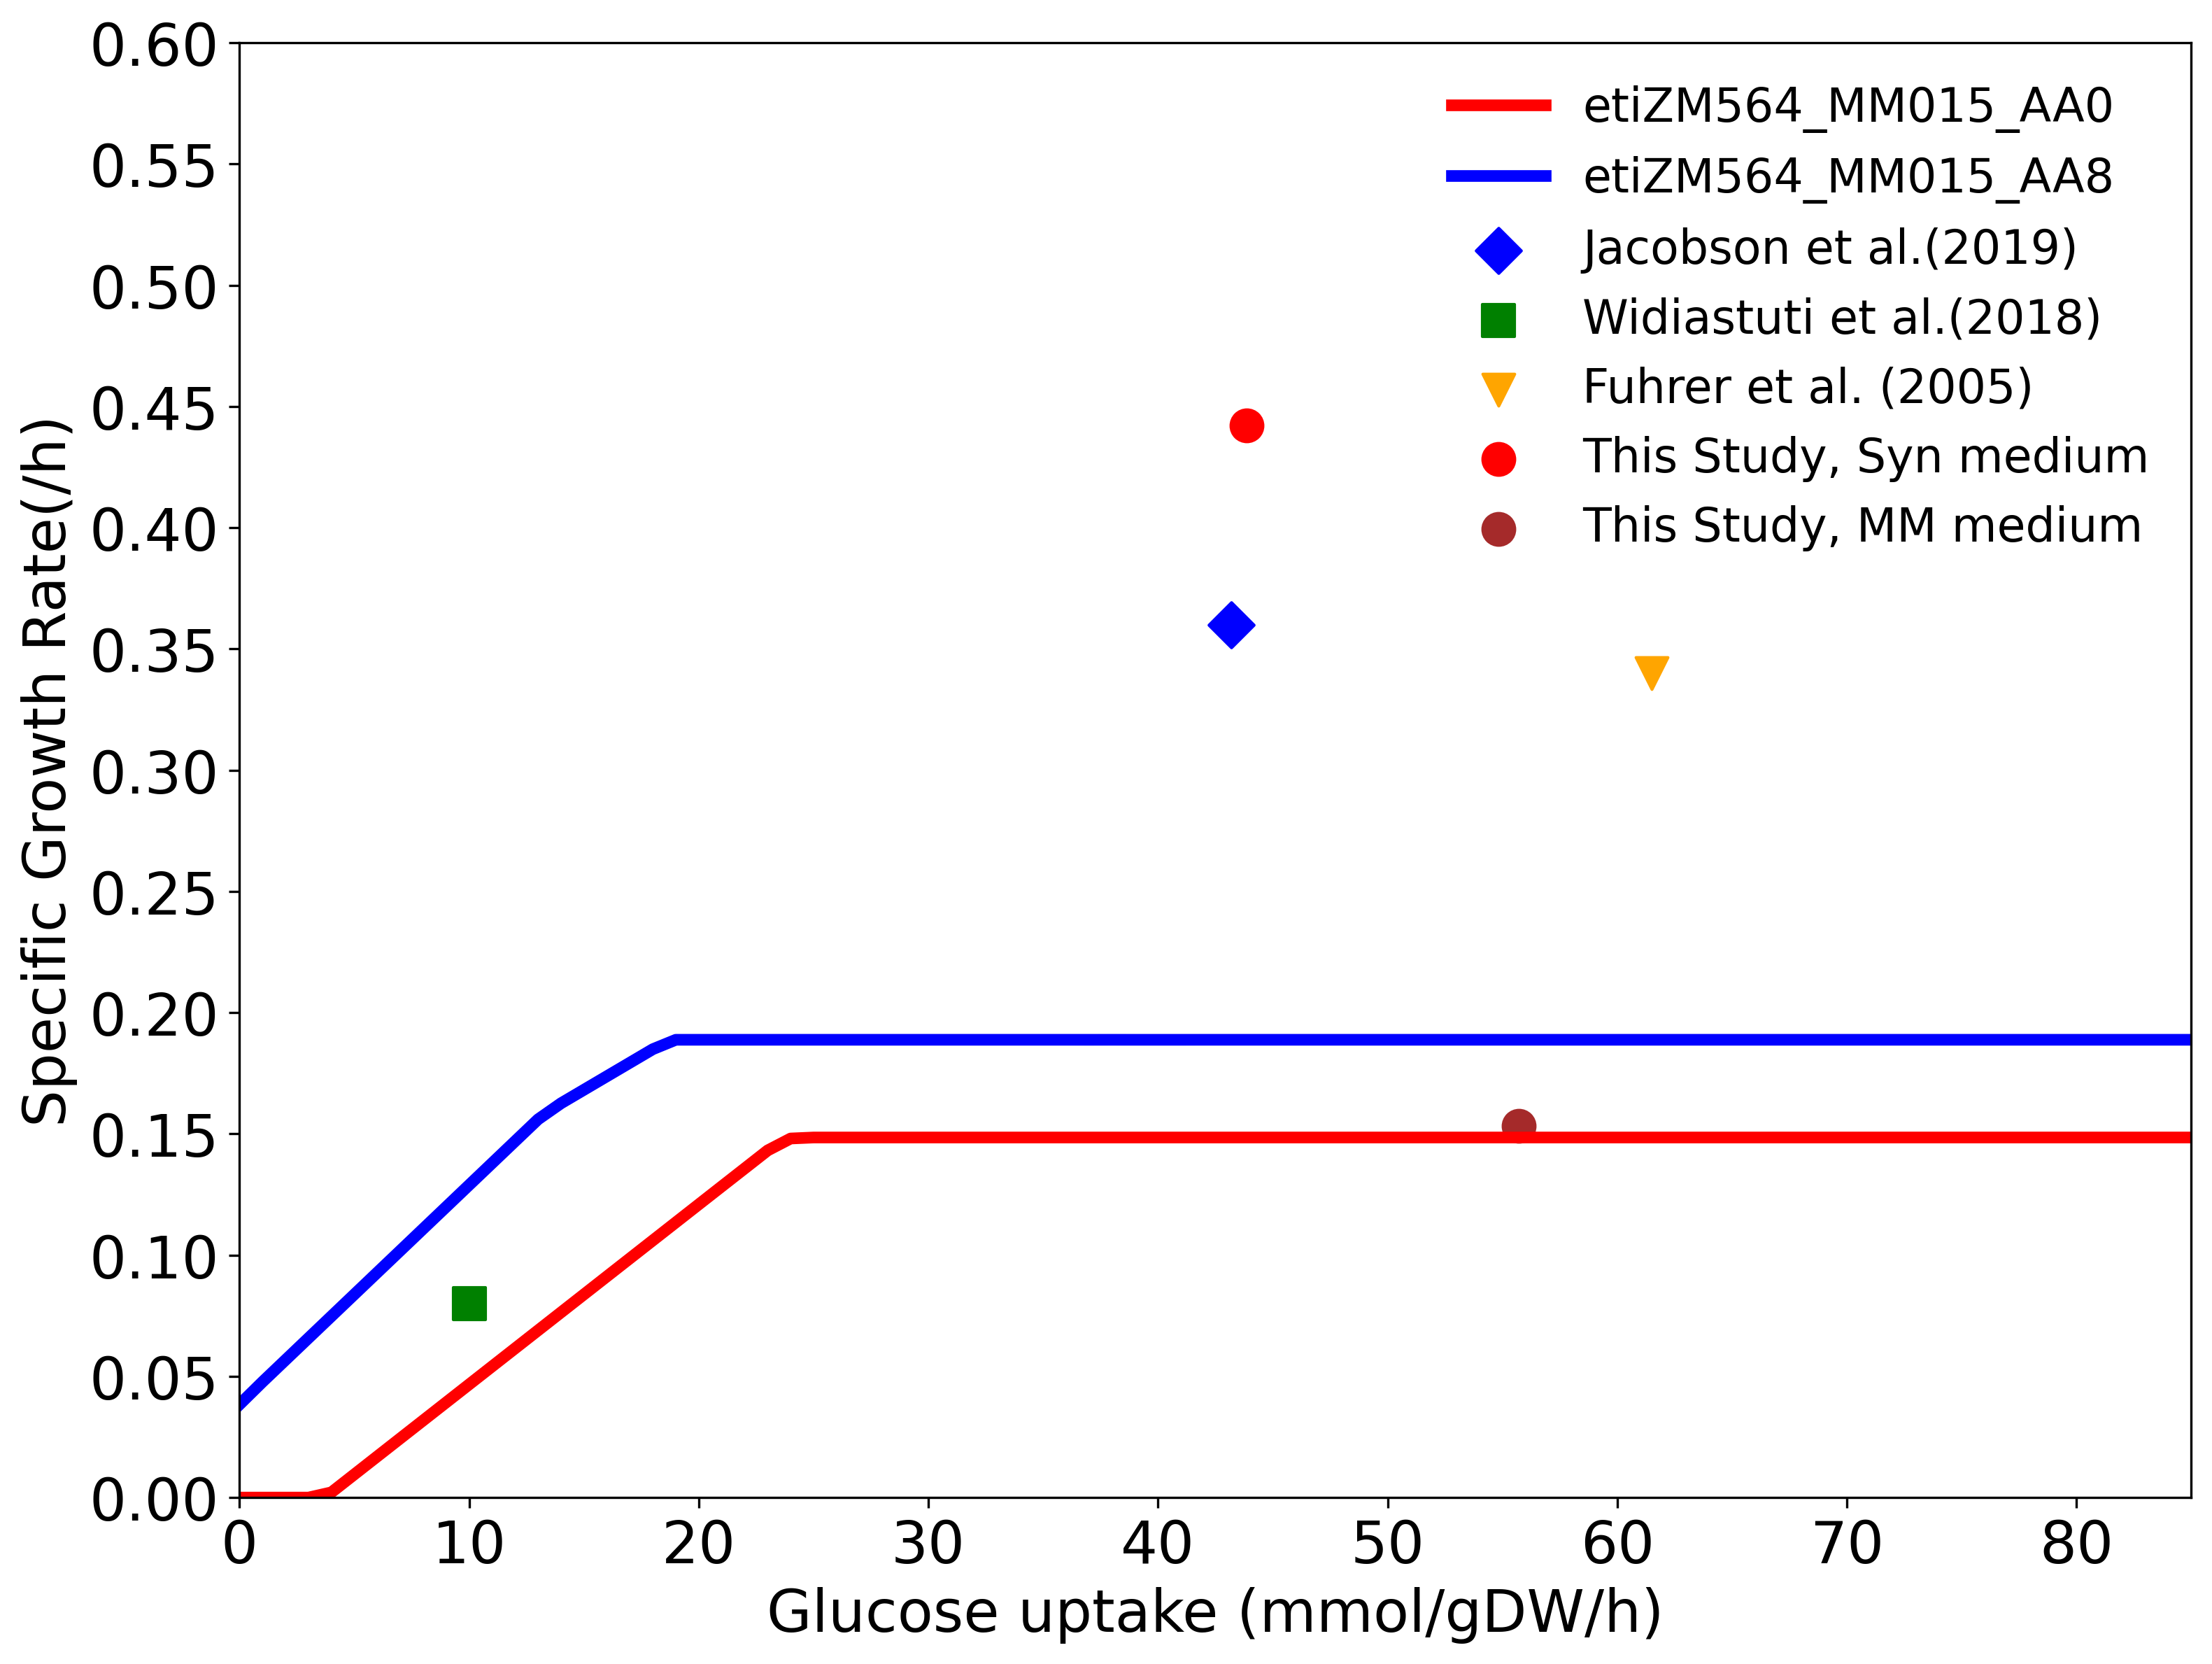

In [7]:
# 创建图形
plt.figure(figsize=(12, 9), dpi=300)
ax = plt.gca()
# 绘制当前 SYN_num 的曲线
for idx, SYN_num in enumerate(SYN_list):
    plt.plot(sub, biomass[SYN_num], label=f"etiZM564_MM015_AA{SYN_num}", 
            linewidth=4, color=colors[idx % len(colors)], markersize=12)
    print(biomass[SYN_num]) 

marker_size = 120
# 添加实验数据点（只添加一次）
plt.scatter(43.2, 0.36, marker='D', color='blue', label="Jacobson et al.(2019)", s=marker_size)
plt.scatter(10, 0.08, marker='s', color='green', label="Widiastuti et al.(2018)", s=marker_size)
plt.scatter(61.5, 0.34, marker='v', color='orange', label="Fuhrer et al. (2005)", s=marker_size)
plt.scatter(43.87, 0.4422, color='red', label="This Study, Syn medium", s=marker_size)
plt.scatter(55.71, 0.1533, color='brown', label="This Study, MM medium", s=marker_size)

# 图形美化
fs = 20
x_min_tick = 0
x_max_tick = np.ceil(max(sub)) if sub else 10
x_tick_step = 10
plt.xticks(np.arange(x_min_tick, x_max_tick + 1, x_tick_step))
plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)
ax.set_yticks(np.arange(0, 0.61, 0.05))
plt.xlabel("Glucose uptake (mmol/gDW/h)", fontsize=fs)
plt.ylabel("Specific Growth Rate(/h)", fontsize=fs)
plt.legend(loc=0, fontsize=fs-4, frameon=False)
ax.set_ylim(0, 0.6)
ax.set_xlim(0, 85)

plt.savefig(f'iZM564_OD_multiple_MM015_comparison.png')
plt.savefig('iZM564_OD_multiple_MM015_comparison.svg')
plt.show()

{0: [None, None, None, None, 7.5097470809153215, 9.443205436204458, 11.726390629604643, 13.293350816163104, 15.487423847670453, 17.36794322920932, 19.248461798058006, 21.128980366906717, 22.94595142132943, 24.873426512178398, 26.77053607345281, 28.651054642301506, 30.531573211150203, 32.412091779998896, 34.292610348847596, 36.1731289176963, 38.05364748654499, 39.93416605539369, 41.81489624606362, 43.69542638526887, 45.249569671722476, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.400629213712136, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.403574992273626, 45.403569885491414, 45.403569885491414, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.40357499227358, 45.403569885491414, 45.40356988549141, 45.40356988549141, 45.40356988549141, 45.40062640399327, 45.40062640399327, 45.40356988549145, 45.40062640399327, 45.40062640399327, 45.40

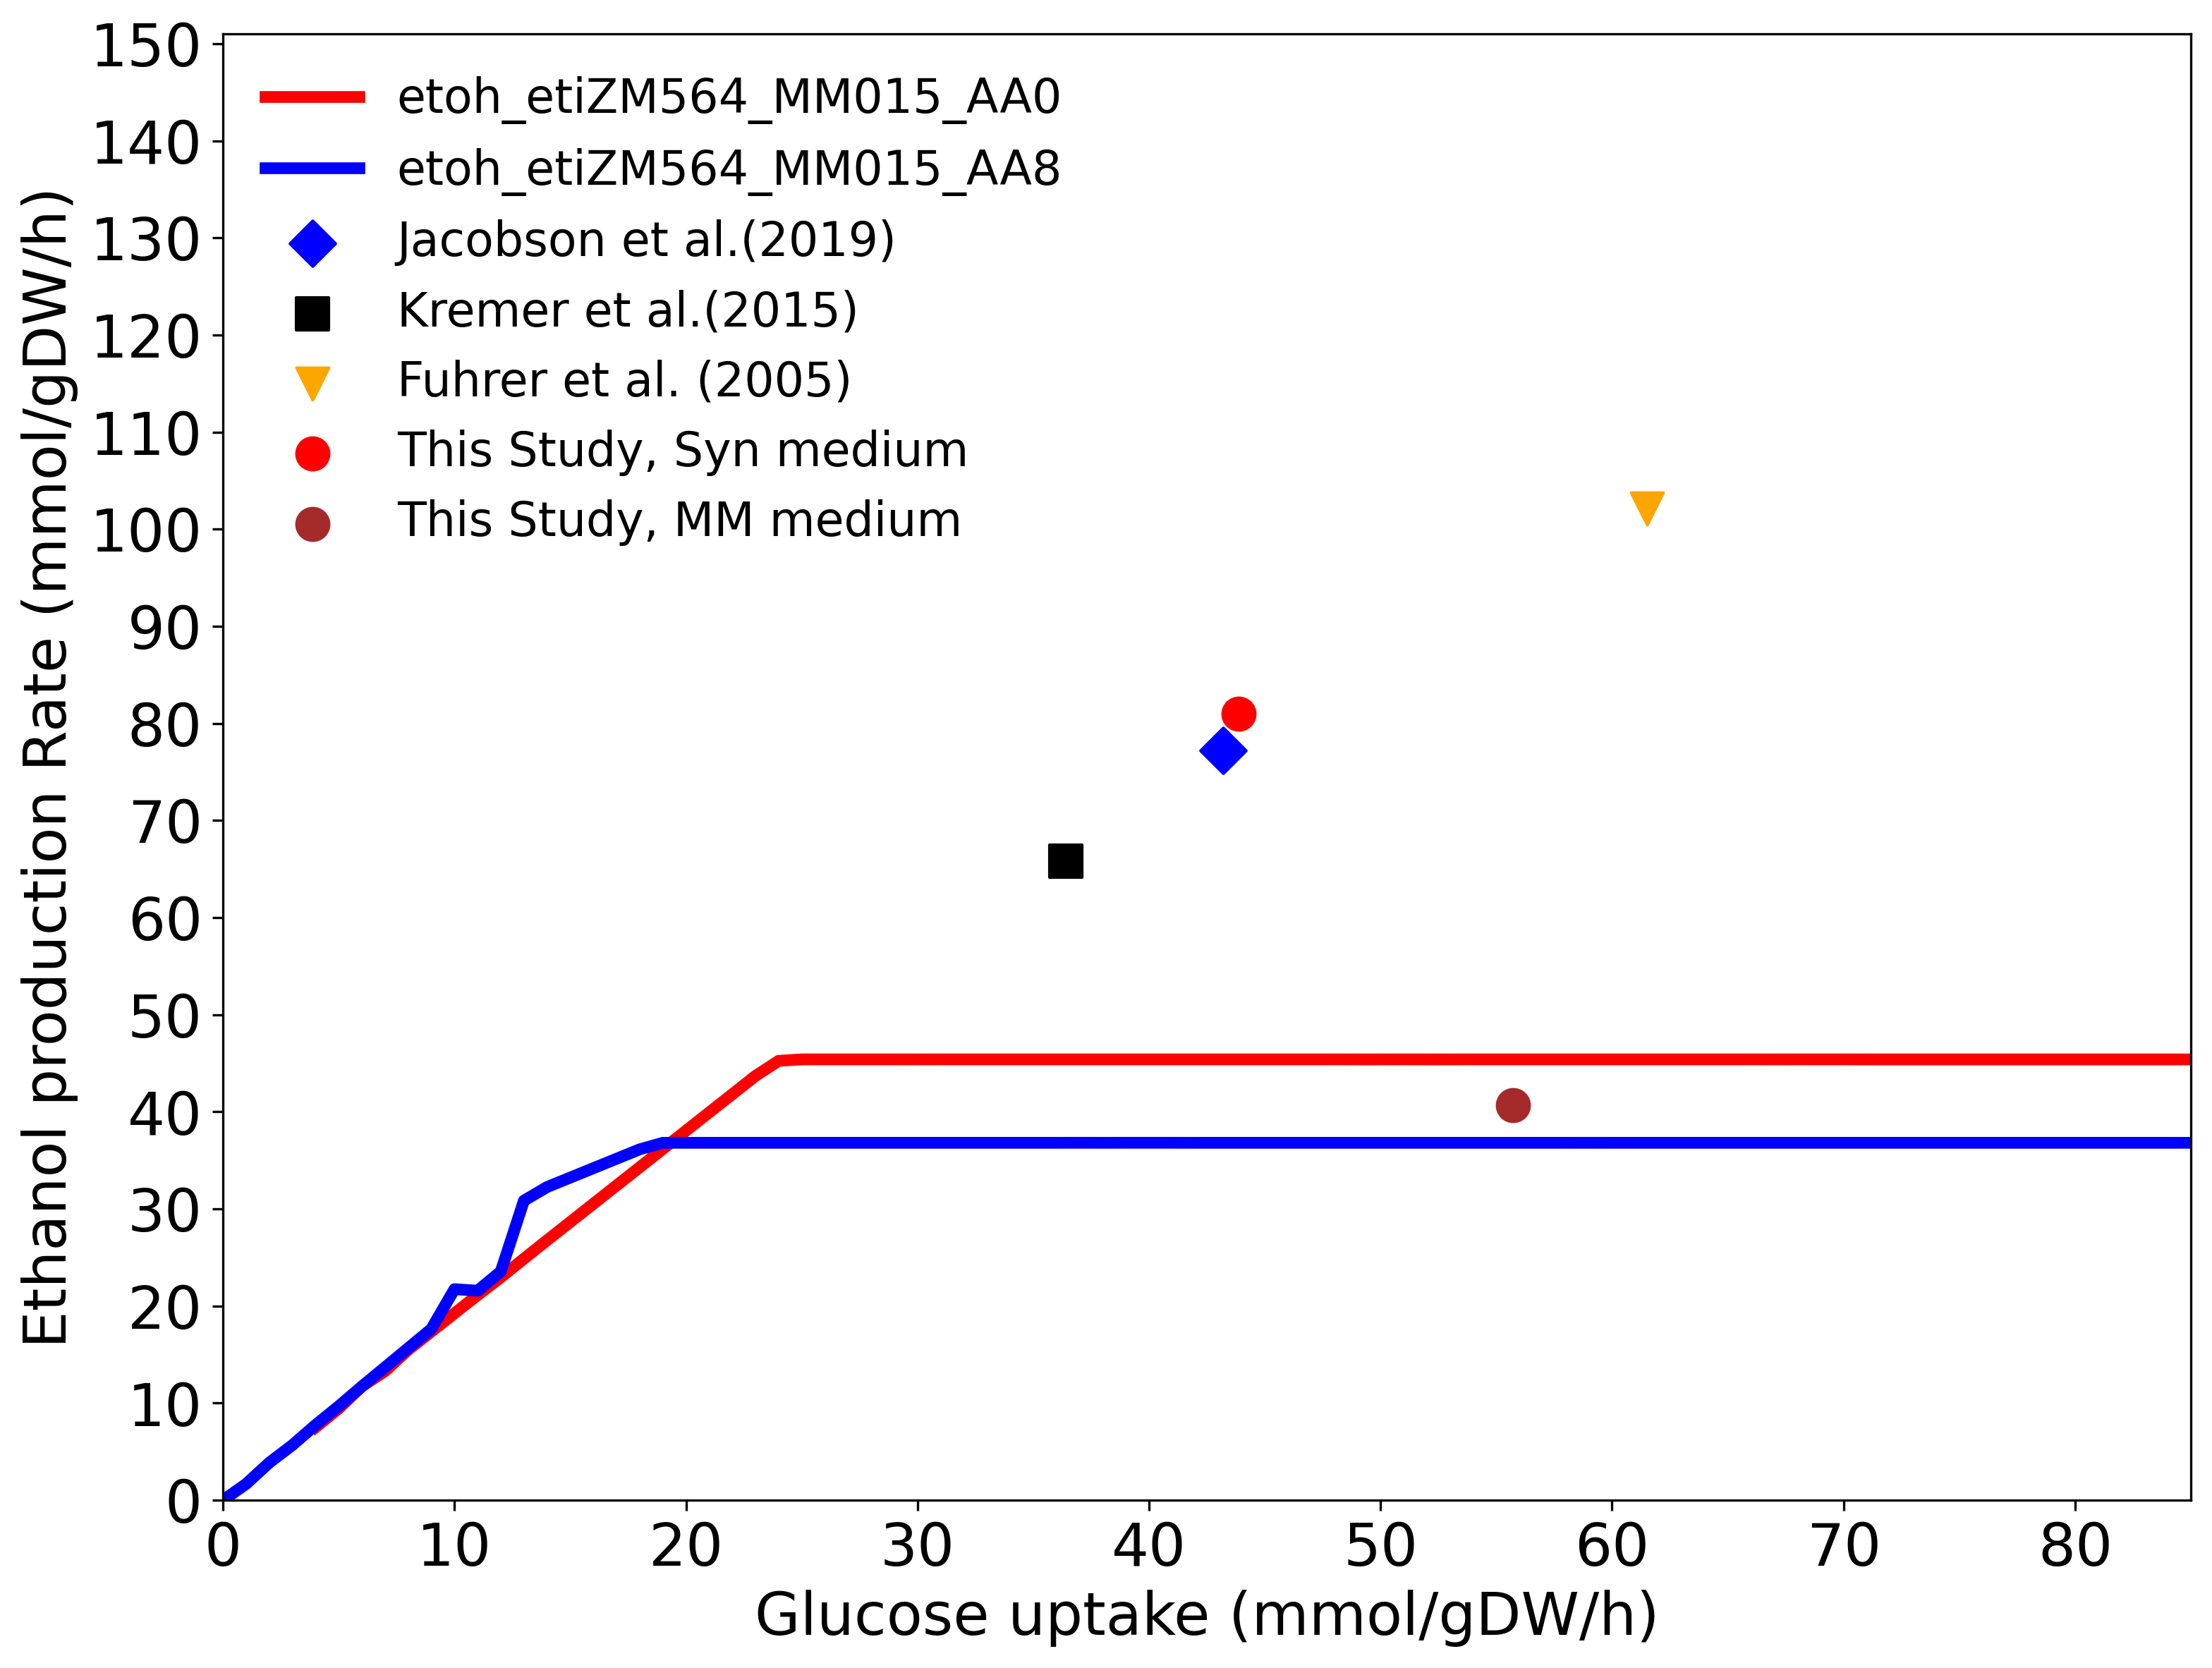

In [8]:
print(etoh)
print(sub)
# 创建图形
plt.figure(figsize=(12, 9), dpi=300)
ax = plt.gca()

# 绘制当前 SYN_num 的曲线
for idx, SYN_num in enumerate(SYN_list):
    plt.plot(sub, etoh[SYN_num], label=f"etoh_etiZM564_MM015_AA{SYN_num}", 
            linewidth=4, color=colors[idx % len(colors)], markersize=12)
#     plt.plot(sub, lac[SYN_num], label=f"etiZM564_SYN{SYN_num}", 
#             linewidth=4, color=colors[-idx % len(colors)], markersize=12)

# 添加实验数据点（只添加一次）
plt.scatter(43.2,77.2,marker = 'D',label="Jacobson et al.(2019)", color = 'blue', s=marker_size)
plt.scatter(36.4,65.8,marker = 's',label="Kremer et al.(2015)", color = 'k', s=marker_size)
plt.scatter(61.5,102.1,marker = 'v',label="Fuhrer et al. (2005)", color = 'orange', s=marker_size)
plt.scatter(43.87,81.01,color = 'red',label="This Study, Syn medium", s=marker_size)
plt.scatter(55.71,40.66,color = 'brown',label="This Study, MM medium", s=marker_size)

# 图形美化
fs = 20
x_min_tick = 0
x_max_tick = np.ceil(max(sub)) if sub else 10
x_tick_step = 10
plt.xticks(np.arange(x_min_tick, x_max_tick + 1, x_tick_step))
plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)
ax.set_yticks(np.arange(0, 151, 10))
plt.xlabel("Glucose uptake (mmol/gDW/h)", fontsize=fs)
plt.ylabel("Ethanol production Rate (mmol/gDW/h)", fontsize=fs)
plt.legend(loc=0, fontsize=fs-4, frameon=False)
ax.set_ylim(0, 151)
ax.set_xlim(0, 85)

plt.savefig(f'iZM564_Ethanol_multiple_MM015_comparison.png')
plt.savefig('iZM564_Ethanol_multiple_MM015_comparison.svg')
plt.show()